In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler ,StandardScaler
from sklearn.decomposition import PCA

print("Libraries imported successfully")

Libraries imported successfully


Create a dataset

In [ ]:
data=pd.DataFrame({
    "Study_Hours": [2,4,5,7,8,10],
    "Attendance_Percentage": [50,60,65,75,85,95],
    "Assignment_Score":[35,45,55,65,80,95],
    "Final_Marks":[38,48,56,68,82,94]
})
display(data)

,Study_Hours,Attendance_Percentage,Assignment_Score,Final_Marks
0,2,50,35,38
1,4,60,45,48
2,5,65,55,56
3,7,75,65,68
4,8,85,80,82
5,10,95,95,94


In [ ]:
features=data[["Study_Hours","Attendance_Percentage","Assignment_Score"]]

print("Minimum values:")
print(features.min())

print("Maximum values:")
print(features.max())

Minimum values:
Study_Hours               2
Attendance_Percentage    50
Assignment_Score         35
dtype: int64
Maximum values:
Study_Hours              10
Attendance_Percentage    95
Assignment_Score         95
dtype: int64


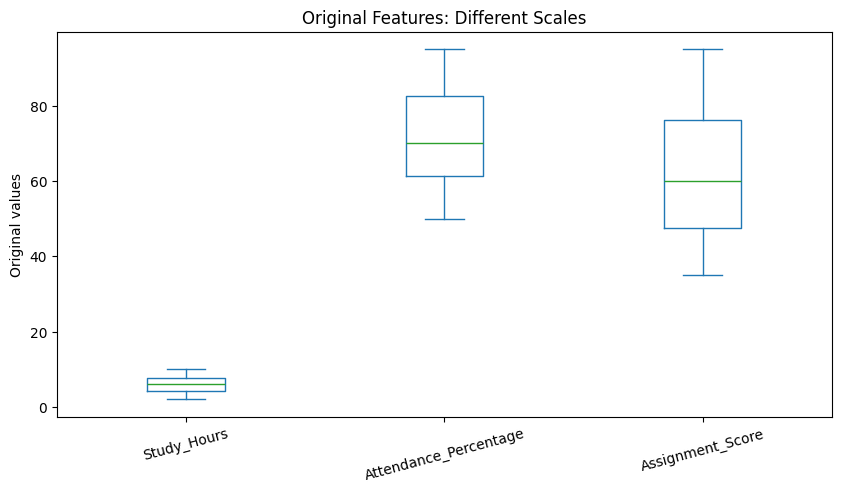

In [ ]:
features.plot(kind="box",figsize=(10,5))
plt.title("Original Features: Different Scales")
plt.ylabel("Original values")
plt.xticks(rotation=15)
plt.show()

In [ ]:
normalizer=MinMaxScaler()
normalized_array=normalizer.fit_transform(features)

normalized_df=pd.DataFrame(normalized_array,columns=features.columns,index=features.index)


display(normalized_df.round(3))

,Study_Hours,Attendance_Percentage,Assignment_Score
0,0.000,0.000,0.000
1,0.250,0.222,0.167
2,0.375,0.333,0.333
3,0.625,0.556,0.500
4,0.750,0.778,0.750
5,1.000,1.000,1.000


In [ ]:
print("Minimum values:")
print(normalized_df.min())

print("Maximum values:")
print(normalized_df.max())

Minimum values:
Study_Hours              0.0
Attendance_Percentage    0.0
Assignment_Score         0.0
dtype: float64
Maximum values:
Study_Hours              1.0
Attendance_Percentage    1.0
Assignment_Score         1.0
dtype: float64


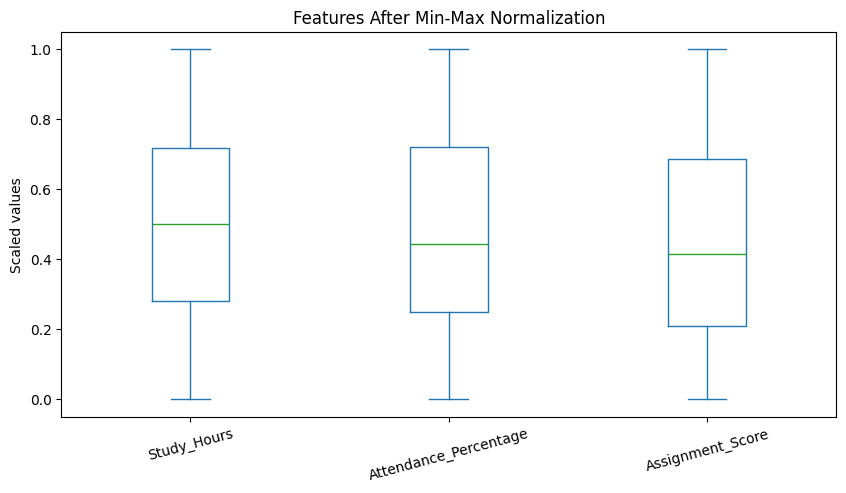

In [ ]:
normalized_df.plot(kind="box",figsize=(10,5))
plt.title("Features After Min-Max Normalization")
plt.ylabel("Scaled values")
plt.xticks(rotation=15)
plt.show()

In [ ]:
standardizer=StandardScaler()
standardise_array=standardizer.fit_transform(features)

standardise_df=pd.DataFrame(standardise_array,columns=features.columns,index=features.index)


display(standardise_df.round(3))

,Study_Hours,Attendance_Percentage,Assignment_Score
0,-1.512,-1.427,-1.351
1,-0.756,-0.768,-0.859
2,-0.378,-0.439,-0.368
3,0.378,0.220,0.123
4,0.756,0.878,0.859
5,1.512,1.537,1.596


In [ ]:
print("Means after standardization:")
print(standardise_df.mean().round(6))

print("Standard deviations after standardization:")
print(standardise_df.std(ddof=0).round(6))

Means after standardization:
Study_Hours              0.0
Attendance_Percentage   -0.0
Assignment_Score         0.0
dtype: float64
Standard deviations after standardization:
Study_Hours              1.0
Attendance_Percentage    1.0
Assignment_Score         1.0
dtype: float64


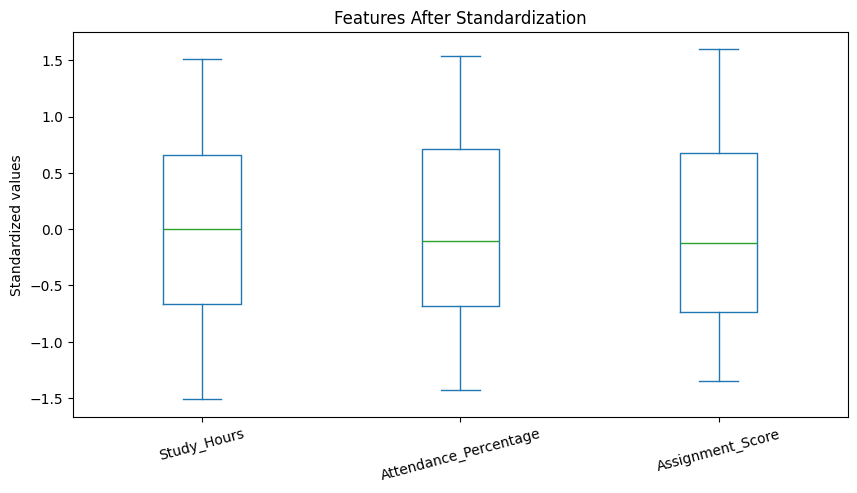

In [ ]:
standardise_df.plot(kind="box",figsize=(10,5))
plt.title("Features After Standardization")
plt.ylabel("Standardized values")
plt.xticks(rotation=15)
plt.show()



*   standardise the input features
*   reduce 3 features to 2 principal components


*   transform the scaled data






In [ ]:
scaled_features=StandardScaler().fit_transform(features)
pca=PCA(n_components=2)
pca_array=pca.fit_transform(scaled_features)
pca_df=pd.DataFrame(pca_array,columns=["PC1","PC2"],index=features.index)
display(pca_df)


,PC1,PC2
0,-2.476452,-0.114569
1,-1.376242,0.068945
2,-0.684425,-0.001284
3,0.415785,0.182231
4,1.439706,-0.078426
5,2.681628,-0.056897


explaine varience by retaining pca

In [ ]:
variance_ratios=pca.explained_variance_ratio_
for component,ratio in zip(["PC1","PC2"],variance_ratios):
    print(f"PC{component}explains {ratio:.2%} of the variance")
total_retained=variance_ratios.sum()
print(f"Total variance retained by 2 components: {total_retained:.2%}")

PCPC1explains 99.62% of the variance
PCPC2explains 0.34% of the variance
Total variance retained by 2 components: 99.96%


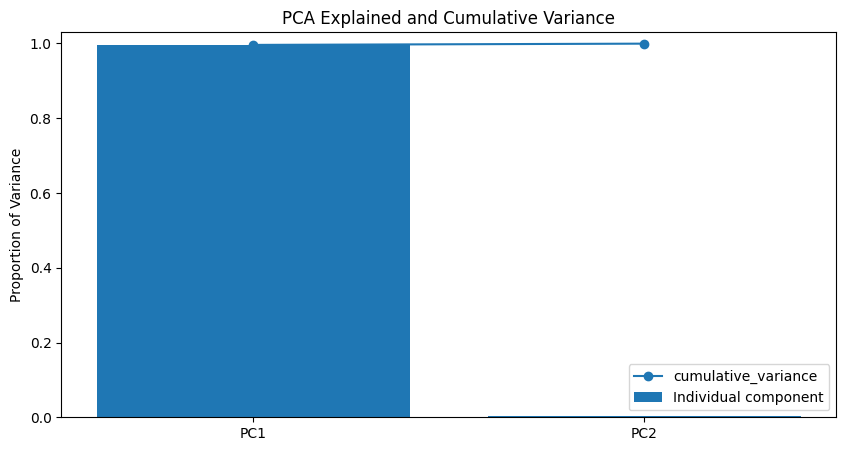

In [ ]:
component_names=["PC1","PC2"]
cumulative_variance=variance_ratios.cumsum()
plt.figure(figsize=(10,5))
plt.bar(component_names,variance_ratios)
plt.plot(component_names,cumulative_variance,marker="o")
plt.ylim(0,1.03)
plt.ylabel("Proportion of Variance")
plt.title("PCA Explained and Cumulative Variance")
plt.legend(["cumulative_variance","Individual component"])
plt.show()